# This is a sample Jupyter Notebook

Below is an example of a code cell. 
Put your cursor into the cell and press Shift+Enter to execute it and select the next one, or click 'Run Cell' button.
Press Double Shift to search everywhere for classes, files, tool windows, actions, and settings.
To learn more about Jupyter Notebooks in PyCharm, see [help](https://www.jetbrains.com/help/pycharm/ipython-notebook-support.html).
For an overview of PyCharm, go to Help -> Learn IDE features or refer to [our documentation](https://www.jetbrains.com/help/pycharm/getting-started.html).

1. DATA OF STARBUCKS STORE (WORLDWIDE)

https://www.kaggle.com/starbucks/store-locations
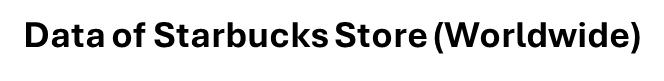
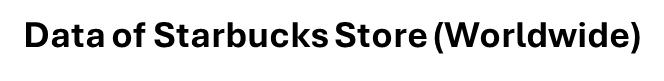
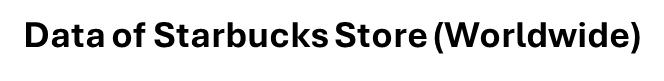

In [23]:
# DATA IMPORT
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests

#//DATA IMPORT
#//Source: https://www.kaggle.com/starbucks/store-locations
#//Option 1A: Choose data from local
# starbuck_data = pd.read_csv(r'C:\Users\Jackie\Desktop\Data Analysis\kaggle\starbucks_location.csv')
#//Option 1B: Choose data online (data upload on GitHub)
import pandas as pd
import io
starbucks_url="https://raw.githubusercontent.com/jackieyong/MBA-2026DA-G3/data/starbucks_location.csv"
starbuck_req=requests.get(starbucks_url).content
starbuck_data=pd.read_csv(io.StringIO(starbuck_req.decode('utf-8')))

#//DATA CLEANING
starbuck_data = starbuck_data.query('Country == "US"')
starbuck_data_drop_columns = ['Brand','Store Name','Store Number','Ownership Type','Phone Number','Timezone','Store Number']
starbuck_data.drop(starbuck_data_drop_columns, inplace=True, axis=1)
starbuck_data.columns = ['address','city','state_ab','country','postcode','long','lat']
starbuck_data.city = starbuck_data.city.astype(str).str.lower()
starbuck_data['city'] = starbuck_data['city'].str.replace(r".","")
starbuck_data['city'] = starbuck_data['city'].str.replace(r",","")
starbuck_data['city'] = starbuck_data['city'].str.replace(r"-"," ")
starbuck_data['city'] = starbuck_data['city'].str.replace(r"'","")
starbuck_data['city'] = starbuck_data['city'].str.replace("saint ","st ")
starbuck_data['city'] = starbuck_data['city'].str.replace("fort ","ft ")
starbuck_data['city'] = starbuck_data['city'].str.replace("mount ","mt ")
starbuck_data.reset_index(inplace=True, drop=True)
starbuck_data

,address,city,state_ab,country,postcode,long,lat
0,5600 Debarr Rd Ste 9,anchorage,AK,US,995042300,-149.78,61.21
1,1725 Abbott Rd,anchorage,AK,US,995073444,-149.84,61.14
2,1501 Huffman Rd,anchorage,AK,US,995153596,-149.85,61.11
3,"320 W. 100th Ave, 100, Southgate Shopping Ctr ...",anchorage,AK,US,99515,-149.89,61.13
4,1005 E Dimond Blvd,anchorage,AK,US,995152050,-149.86,61.14
...,...,...,...,...,...,...,...
13603,554 N 3rd St,laramie,WY,US,820723012,-105.59,41.32
13604,3112 E. Grand,laramie,WY,US,820705141,-105.56,41.31
13605,3021 Grand Ave,laramie,WY,US,82070,-105.56,41.31
13606,118 Westland Way,rock springs,WY,US,829015751,-109.25,41.58


In [24]:
total_store = starbuck_data.shape[0]
print('It is discovered that there are “',total_store,'” Starbucks stores in US.')

It is discovered that there are “ 13608 ” Starbucks stores in US.


In [25]:
#//DATA GROUPED BY CITY
starbuck_group = starbuck_data.groupby(['city','state_ab']).size().reset_index(name='store_count')
starbuck_group = starbuck_group.sort_values('store_count', ascending=True)
starbuck_group.reset_index(inplace=True, drop=True)
starbuck_group['store_count'] = starbuck_group['store_count'].astype(float)
starbuck_group

,city,state_ab,store_count
0,woodstock,IL,1.0
1,woodstock,OR,1.0
2,woodway,TX,1.0
3,wooster,OH,1.0
4,worthington,OH,1.0
...,...,...,...
3567,houston,TX,154.0
3568,seattle,WA,156.0
3569,las vegas,NV,157.0
3570,chicago,IL,182.0


In [26]:
total_city_set = starbuck_group.shape[0]
print('After groupby, there are',total_city_set,'cities that has at least one Starbucks in US.')

After groupby, there are 3572 cities that has at least one Starbucks in US.


In [27]:
#//PLOT MAP (ONLY SHOW TOP 1500 CITIES)
tile_url = "https://basemaps.cartocdn.com/light_all/{z}/{x}/{y}.png?key=cb1_4j3a_1_f77b957d78e1884019158ba0"
import folium
starbuck_group_geo = starbuck_data.groupby(['city','state_ab']).agg({'long': 'median', 'lat': 'median'})
starbuck_group_geo.reset_index(inplace=True, drop=False)
star_city_geo = pd.merge(starbuck_group, starbuck_group_geo, how='left', on=['city', 'state_ab'])
star_city_geo = star_city_geo.tail(1500)
m = folium.Map(
    location=[38, -110],
    tiles=tile_url,
    zoom_start=4,
    width='100%',
    height='100%',
    attr='CARTO'
)

for i in range(0,len(star_city_geo)):
   folium.Circle(
       location=[star_city_geo['lat'].iloc[i], star_city_geo['long'].iloc[i]],
       popup=star_city_geo['city'].iloc[i],
       radius=star_city_geo['store_count'].iloc[i]*2000,
       color=False,
       fill=True,
       fill_color='#009933', fill_opacity=0.5,
   ).add_to(m)
plot_map = folium.Figure(width='100%', height=500)
m.add_to(plot_map)
plot_map

From choropleth map, it can be easily discovered that Starbucks' store density is accumulated around east and west coast.

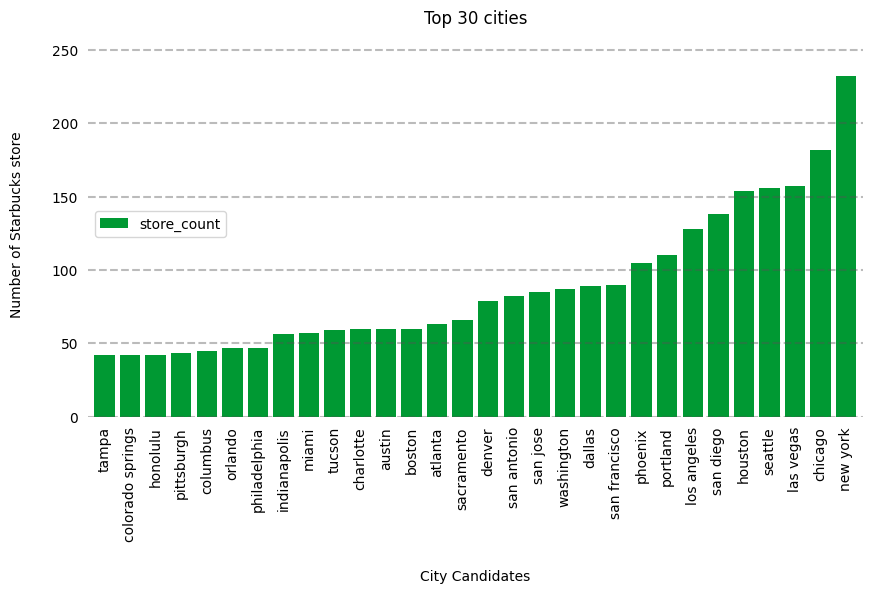

In [28]:
#//PLOT BARCHART (GROUPED BY CITY)
#//Data for plot
starbuck_city_plot = starbuck_group.tail(30)
starbuck_city_plot.reset_index(inplace=True, drop=True)
# //Plot
ax = starbuck_city_plot.plot(kind='bar', x='city', y='store_count', figsize=(10, 5), color='#009933', width=0.8)
ax.set_title('Top 30 cities')
# //Disable spines
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
# //Switch off ticks
ax.tick_params(axis="both", which="both", bottom=False, top=False, labelbottom=True, left=False, right=False, labelleft=True)
# //Set x-axis label
ax.set_xlabel("City Candidates", labelpad=20)
# //Set y-axis label
ax.set_ylabel("Number of Starbucks store", labelpad=20)
# //Draw vertical axis lines
vals = ax.get_yticks()
for tick in vals:
    ax.axhline(y=tick, linestyle='dashed', alpha=0.4, color='#555555', zorder=1)
plt.show()

2. DEMOGRAPHIC DATA (US）

City data (all level population) is collected, features include: city, state, population, gender, age median, marriage conditions, mortgage, high school education, household income and family income.

- https://www.kaggle.com/datasets/goldenoakresearch/us-acs-mortgage-equity-loans-rent-statistics
- https://www.kaggle.com/datasets/washimahmed/usa-latlong-for-state-abbreviations

In [29]:
#//DATA IMPORT
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
pd.set_option('display.max_columns', None)  # or 1000
#us_city2 = pd.read_csv(r'C:\Users\ASUS\Downloads\us-acs-mortgage-equity-loans-rent-statistics\real_estate_db_utf8.csv')
#DATA SOURCE: https://www.kaggle.com/datasets/goldenoakresearch/us-acs-mortgage-equity-loans-rent-statistics
us_city2_url="https://raw.githubusercontent.com/jackieyong/MBA-2026DA-G3/data/real_estate_db_utf8.csv"
us_city2_req=requests.get(us_city2_url).content
us_city2=pd.read_csv(io.StringIO(us_city2_req.decode('utf-8')))
us_city2.columns = us_city2.columns.str.strip()

#//REMOVE DUPLICATES
us_city2.drop_duplicates(subset='UID', keep='first', inplace=True)
us_city2 = us_city2.reset_index(drop=True)

#//CHECK NULL (暂时不用)
#null_columns=us_city2.columns[us_city2.isnull().any()]
#us_city2[null_columns].isnull().sum()

#//UNIFIED CITY NAME
# us_city2['city'] = us_city2['city'].str.replace(
#     r'(?<!west )\bNew York\b',
#     'Manhattan',
#     regex=True
# )

#//DROP UNWANTED + INVALID + NULL COLUMN
drop_key = ['mean', 'sample', 'stdev', 'cdf']
drop_contain = [c for c in us_city2.columns if any(k in c for k in drop_key)]
drop_exact = ['UID','BLOCKID','place','type','zip_code','lat','lng','SUMLEVEL','COUNTYID','STATEID',
              'state','primary','area_code','pct_own','married_snp']
drop_cols = list(dict.fromkeys(drop_contain + drop_exact))
us_city2.drop(columns=drop_cols, inplace=True, errors='ignore')

#//REFINE CITY NAME TO ENSURE CONSISTENCE
us_city2['city'] = us_city2['city'].astype(str).str.lower().str.strip()
us_city2['city'] = us_city2['city'].str.replace('–', ' ', regex=False)
us_city2['city'] = us_city2['city'].str.replace('.', '', regex=False)
us_city2['city'] = us_city2['city'].str.replace('-', ' ', regex=False)
us_city2['city'] = us_city2['city'].str.replace(',', '', regex=False)
us_city2['city'] = us_city2['city'].str.replace("'", '', regex=False)
us_city2['city'] = us_city2['city'].str.replace('saint ', 'st ', regex=False)
us_city2['city'] = us_city2['city'].str.replace('fort ', 'ft ', regex=False)
us_city2['city'] = us_city2['city'].str.replace('mount ', 'mt ', regex=False)
us_city2['city'] = us_city2['city'].str.replace(r'\s+', ' ', regex=True).str.strip()

#//ENSURE NUMERICAL VALUE IS NOT OBJECT
num_cols = ['ALand','AWater','pop','male_pop','female_pop']
for c in num_cols:
    if c in us_city2.columns:
        us_city2[c] = pd.to_numeric(us_city2[c], errors='coerce')
us_city2.dropna(subset=[c for c in num_cols if c in us_city2.columns], inplace=True)

#//CALCULATE POPULATION RATIO
us_city2['male_pop_ratio'] = us_city2['male_pop'] / us_city2['pop']
us_city2['female_pop_ratio'] = us_city2['female_pop'] / us_city2['pop']

#//GROUP A: SELECT SEVERAL COLUMNS TO FORM A WORKING COPY, CALCULATE SUM, ADD [POPULATION DENSITY]
a_cols = ['state_ab','city','ALand','AWater','pop','male_pop','female_pop']
us_city2_a = us_city2[a_cols].copy()
us_city2_a.columns = ['state_ab','city','land_area','water_area',
                      'population','male_population','female_population']
us_city2_a = us_city2_a.groupby(['state_ab','city'], as_index=False).sum()
us_city2_a['population_density'] = us_city2_a['population'] / us_city2_a['land_area'].replace(0, pd.NA)

#//GROUP B: SELECT SEVERAL COLUMNS TO FORM A WORKING COPY, CALCULATE MEDIAN
b_drop = ['ALand','AWater','pop','male_pop','female_pop','male_pop_ratio','female_pop_ratio']
us_city2_b = us_city2.drop(columns=b_drop, errors='ignore').copy()
us_city2_b = us_city2_b.groupby(['state_ab','city'], as_index=False).median(numeric_only=True)

#//MERGE GROUP A + B
for df in (us_city2_a, us_city2_b):
    df['state_ab'] = df['state_ab'].astype(str)
    df['city'] = df['city'].astype(str)
us_city2_merge = pd.merge(us_city2_a, us_city2_b, how='left', on=['state_ab','city'])
us_city2_merge

,state_ab,city,land_area,water_area,population,male_population,female_population,population_density,rent_median,rent_gt_10,rent_gt_15,rent_gt_20,rent_gt_25,rent_gt_30,rent_gt_35,rent_gt_40,rent_gt_50,hi_median,family_median,hc_mortgage_median,hc_median,home_equity_second_mortgage,second_mortgage,home_equity,debt,hs_degree,hs_degree_male,hs_degree_female,male_age_median,female_age_median,married,separated,divorced
0,AK,anchorage,1.102774e+09,493687174,150561,77433,73128,1.365294e-04,1173.0,0.97040,0.85551,0.68289,0.55106,0.40760,0.31366,0.22814,0.14330,68853.0,80652.0,1816.0,661.0,0.02062,0.02062,0.06014,0.69528,0.93358,0.91967,0.93691,33.08333,34.00000,0.44428,0.01186,0.11328
1,AK,copper center,6.395523e+10,1214891934,2554,1298,1256,3.993418e-08,663.0,0.85294,0.72059,0.65441,0.45588,0.36029,0.33088,0.30882,0.12500,44145.0,58169.0,1417.0,307.0,0.00661,0.00661,0.00992,0.33719,0.87655,0.84605,0.90561,36.00000,35.33333,0.43071,0.00798,0.07976
2,AK,craig,3.358007e+08,84392388,2513,1326,1187,7.483606e-06,852.0,0.95219,0.81673,0.66534,0.49004,0.38247,0.26693,0.23506,0.15139,58058.0,73299.0,1484.0,382.0,0.00481,0.01442,0.02404,0.40064,0.89420,0.89153,0.89721,41.58333,39.58333,0.46409,0.02118,0.14641
3,AK,delta junction,1.729676e+10,376371361,4794,2742,2052,2.771618e-07,1293.0,0.86704,0.70637,0.60665,0.54017,0.41551,0.27701,0.22715,0.13850,75492.0,79386.0,1465.0,517.0,0.00000,0.00000,0.01752,0.38116,0.93997,0.94775,0.92934,35.58333,35.83333,0.57439,0.00565,0.11535
4,AK,dillingham,4.096520e+08,7194810,2335,1144,1191,5.699960e-06,1057.0,0.93590,0.80769,0.61538,0.50321,0.37179,0.26923,0.21474,0.13782,65062.0,78688.0,1891.0,587.0,0.00000,0.00000,0.02113,0.49296,0.93653,0.92758,0.94571,33.75000,32.25000,0.48237,0.02162,0.11832
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11274,WY,torrington,8.794984e+07,927985,5571,3062,2509,6.334292e-05,687.0,0.96673,0.83549,0.69871,0.48059,0.25323,0.20333,0.16081,0.08872,43662.0,61909.0,1016.0,381.0,0.02703,0.03311,0.06486,0.53041,0.92816,0.93051,0.92528,39.50000,42.08333,0.47508,0.00729,0.18060
11275,WY,upton,6.100270e+09,4817928,3442,1998,1444,5.642373e-07,728.0,0.79630,0.48148,0.32870,0.28241,0.15741,0.11111,0.07870,0.03241,69215.0,88659.0,1412.0,382.0,0.00453,0.00453,0.02267,0.43155,0.90238,0.90413,0.89991,45.16667,47.16667,0.54247,0.00906,0.14609
11276,WY,wheatland,2.289550e+09,61606458,2254,1208,1046,9.844730e-07,785.0,0.89730,0.67027,0.61622,0.49189,0.46486,0.46486,0.44324,0.24865,51546.0,60152.0,1110.0,307.0,0.02838,0.02838,0.02973,0.51081,0.93384,0.94962,0.91519,51.41667,48.16667,0.54151,0.00849,0.16698
11277,WY,worland,1.993203e+06,0,2578,1264,1314,1.293396e-03,630.0,0.97882,0.89882,0.71529,0.49647,0.44235,0.36706,0.19529,0.10824,32883.0,58014.0,862.0,333.0,0.05200,0.05200,0.07333,0.54533,0.84651,0.77739,0.91290,38.75000,35.16667,0.47577,0.01211,0.29185


In [30]:
#//DATA INTEGRATION: MERGE DEMOGRAPHIC DATA WITH STORE DATA, NON-MATCHED DATA IS AUTOMATICALLY REMOVED
star_us_city = pd.merge(us_city2_merge, starbuck_group, how='left', on=['state_ab', 'city'])
star_us_city.dropna(axis=0, how='any', inplace=True)
star_us_city.reset_index(inplace=True, drop=True)
star_us_city

,state_ab,city,land_area,water_area,population,male_population,female_population,population_density,rent_median,rent_gt_10,rent_gt_15,rent_gt_20,rent_gt_25,rent_gt_30,rent_gt_35,rent_gt_40,rent_gt_50,hi_median,family_median,hc_mortgage_median,hc_median,home_equity_second_mortgage,second_mortgage,home_equity,debt,hs_degree,hs_degree_male,hs_degree_female,male_age_median,female_age_median,married,separated,divorced,store_count
0,AK,anchorage,1.102774e+09,493687174,150561,77433,73128,1.365294e-04,1173.0,0.970400,0.855510,0.682890,0.551060,0.407600,0.31366,0.228140,0.143300,68853.0,80652.0,1816.0,661.0,0.020620,0.020620,0.060140,0.695280,0.933580,0.919670,0.936910,33.083330,34.000000,0.444280,0.011860,0.113280,24.0
1,AK,eagle river,5.092349e+08,1859309,3727,1780,1947,7.318823e-06,2351.0,0.795450,0.568180,0.568180,0.454550,0.204550,0.20455,0.204550,0.000000,119141.0,143026.0,2306.0,742.0,0.036090,0.060780,0.074070,0.756890,0.940900,0.972530,0.915030,39.333330,39.666670,0.523810,0.007820,0.135750,3.0
2,AK,fairbanks,1.420075e+10,111522358,68049,36424,31625,4.791931e-06,1075.0,0.979620,0.914120,0.760350,0.632090,0.472390,0.36801,0.318700,0.213100,69093.0,84847.0,1931.5,726.5,0.008480,0.008480,0.039885,0.674640,0.931500,0.944810,0.953840,31.500000,34.333330,0.471940,0.015000,0.107710,5.0
3,AK,juneau,6.848156e+09,1422171690,20429,10713,9716,2.983139e-06,1146.5,0.941665,0.881045,0.621380,0.462580,0.370845,0.26865,0.226535,0.147050,83072.5,109234.5,2203.0,694.0,0.021950,0.032465,0.070830,0.713990,0.965590,0.976525,0.948410,39.750000,41.041670,0.516385,0.023515,0.105400,2.0
4,AK,ketchikan,1.257611e+10,4648192104,10677,5478,5199,8.489909e-07,1175.0,0.950000,0.881820,0.631820,0.450000,0.340910,0.24390,0.229970,0.132400,86566.0,97924.0,1745.0,617.0,0.010610,0.021220,0.080460,0.674060,0.938160,0.920550,0.954970,36.916670,40.166670,0.530980,0.007630,0.135370,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2956,WY,gillette,5.936005e+09,6699390,21183,11145,10038,3.568562e-06,1045.0,0.863560,0.818640,0.591840,0.430610,0.387550,0.33522,0.229620,0.128120,78694.0,86579.0,1432.0,398.0,0.038320,0.038320,0.038320,0.679660,0.935700,0.949750,0.921700,32.583330,33.583330,0.553860,0.017800,0.056050,2.0
2957,WY,jackson,7.781997e+07,845971,7986,3960,4026,1.026215e-04,1111.0,0.847590,0.828930,0.737950,0.494560,0.315710,0.22628,0.202950,0.097980,81817.0,89600.0,2045.0,468.0,0.036020,0.036020,0.118440,0.727720,0.942840,0.970830,0.912190,37.416670,36.000000,0.504830,0.048900,0.087260,2.0
2958,WY,lander,5.266600e+07,0,7636,3783,3853,1.449892e-04,698.5,0.960200,0.802860,0.700335,0.599225,0.403260,0.35796,0.319885,0.297705,52734.0,72574.5,1325.5,369.0,0.034740,0.034740,0.058020,0.622140,0.956995,0.923985,0.986175,38.333335,41.916665,0.515330,0.005715,0.151180,1.0
2959,WY,laramie,6.825149e+08,10167664,22720,11888,10832,3.328865e-05,796.0,0.976525,0.916045,0.832185,0.762880,0.659680,0.58716,0.497520,0.389715,42701.5,63354.0,1398.0,417.0,0.022535,0.036305,0.061390,0.648335,0.964475,0.972310,0.980410,27.166665,28.125000,0.435260,0.000000,0.060245,3.0


Since the final valid city demographic data only have 2961 cities, after data cleaning and integrated with Starbucks store data,
nearly 611 (3572-2961) cities are removed from demographic dataset. In terms of Starbucks store, 792 out of 12816, i.e., 5.82% of data is invalid.

In [31]:
#//CHECK INVALID STORE DATA RATIO
valid_s = star_us_city['store_count'].sum()
invalid_s = starbuck_data.shape[0] - valid_s
invalid_per_s = invalid_s / starbuck_data.shape[0] * 100
print('Final valid number of Starbucks stores:', valid_s,'\n'
      'Invalid number of Starbucks stores:', invalid_s,'\n'
     'Invalid percentage of Starbucks stores:',invalid_per_s, '%')

Final valid number of Starbucks stores: 12816.0 
Invalid number of Starbucks stores: 792.0 
Invalid percentage of Starbucks stores: 5.82010582010582 %


In [32]:
#//REVEAL THE NON MATCHED DATA (LEFT ONLY / RIGHT ONLY)
star_us_city_invalid = pd.merge(us_city2_merge, starbuck_group, how='outer', indicator=True, on=['state_ab', 'city'])
star_us_city_invalid

,state_ab,city,land_area,water_area,population,male_population,female_population,population_density,rent_median,rent_gt_10,rent_gt_15,rent_gt_20,rent_gt_25,rent_gt_30,rent_gt_35,rent_gt_40,rent_gt_50,hi_median,family_median,hc_mortgage_median,hc_median,home_equity_second_mortgage,second_mortgage,home_equity,debt,hs_degree,hs_degree_male,hs_degree_female,male_age_median,female_age_median,married,separated,divorced,store_count,_merge
0,AK,anchorage,1.102774e+09,4.936872e+08,150561.0,77433.0,73128.0,1.365294e-04,1173.0,0.97040,0.85551,0.68289,0.55106,0.40760,0.31366,0.22814,0.14330,68853.0,80652.0,1816.0,661.0,0.02062,0.02062,0.06014,0.69528,0.93358,0.91967,0.93691,33.08333,34.00000,0.44428,0.01186,0.11328,24.0,both
1,AK,copper center,6.395523e+10,1.214892e+09,2554.0,1298.0,1256.0,3.993418e-08,663.0,0.85294,0.72059,0.65441,0.45588,0.36029,0.33088,0.30882,0.12500,44145.0,58169.0,1417.0,307.0,0.00661,0.00661,0.00992,0.33719,0.87655,0.84605,0.90561,36.00000,35.33333,0.43071,0.00798,0.07976,NaN,left_only
2,AK,craig,3.358007e+08,8.439239e+07,2513.0,1326.0,1187.0,7.483606e-06,852.0,0.95219,0.81673,0.66534,0.49004,0.38247,0.26693,0.23506,0.15139,58058.0,73299.0,1484.0,382.0,0.00481,0.01442,0.02404,0.40064,0.89420,0.89153,0.89721,41.58333,39.58333,0.46409,0.02118,0.14641,NaN,left_only
3,AK,delta junction,1.729676e+10,3.763714e+08,4794.0,2742.0,2052.0,2.771618e-07,1293.0,0.86704,0.70637,0.60665,0.54017,0.41551,0.27701,0.22715,0.13850,75492.0,79386.0,1465.0,517.0,0.00000,0.00000,0.01752,0.38116,0.93997,0.94775,0.92934,35.58333,35.83333,0.57439,0.00565,0.11535,NaN,left_only
4,AK,dillingham,4.096520e+08,7.194810e+06,2335.0,1144.0,1191.0,5.699960e-06,1057.0,0.93590,0.80769,0.61538,0.50321,0.37179,0.26923,0.21474,0.13782,65062.0,78688.0,1891.0,587.0,0.00000,0.00000,0.02113,0.49296,0.93653,0.92758,0.94571,33.75000,32.25000,0.48237,0.02162,0.11832,NaN,left_only
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11869,WY,torrington,8.794984e+07,9.279850e+05,5571.0,3062.0,2509.0,6.334292e-05,687.0,0.96673,0.83549,0.69871,0.48059,0.25323,0.20333,0.16081,0.08872,43662.0,61909.0,1016.0,381.0,0.02703,0.03311,0.06486,0.53041,0.92816,0.93051,0.92528,39.50000,42.08333,0.47508,0.00729,0.18060,NaN,left_only
11870,WY,upton,6.100270e+09,4.817928e+06,3442.0,1998.0,1444.0,5.642373e-07,728.0,0.79630,0.48148,0.32870,0.28241,0.15741,0.11111,0.07870,0.03241,69215.0,88659.0,1412.0,382.0,0.00453,0.00453,0.02267,0.43155,0.90238,0.90413,0.89991,45.16667,47.16667,0.54247,0.00906,0.14609,NaN,left_only
11871,WY,wheatland,2.289550e+09,6.160646e+07,2254.0,1208.0,1046.0,9.844730e-07,785.0,0.89730,0.67027,0.61622,0.49189,0.46486,0.46486,0.44324,0.24865,51546.0,60152.0,1110.0,307.0,0.02838,0.02838,0.02973,0.51081,0.93384,0.94962,0.91519,51.41667,48.16667,0.54151,0.00849,0.16698,NaN,left_only
11872,WY,worland,1.993203e+06,0.000000e+00,2578.0,1264.0,1314.0,1.293396e-03,630.0,0.97882,0.89882,0.71529,0.49647,0.44235,0.36706,0.19529,0.10824,32883.0,58014.0,862.0,333.0,0.05200,0.05200,0.07333,0.54533,0.84651,0.77739,0.91290,38.75000,35.16667,0.47577,0.01211,0.29185,NaN,left_only


3. NEIGHBOURHOOD DATA (NY-MANHATTAN）

Beside city level, we also want to study the correlation of features in a more zoom in scale, which is neighborhood. From 2 we found that NY-MANHATTAN has the highest number of Starbucks store. Firstly, to investigate the geographical data of Starbuck stores' location in NY-MANHATTAN.

In [33]:
star_man_data = starbuck_data.query('city == "new york" & state_ab == "NY"')
star_man_group = star_man_data.groupby(['long','lat']).size().reset_index(name='store_count')
star_man_group['store_count'] = star_man_group['store_count'].astype(float)
star_man_group

,long,lat,store_count
0,-74.02,40.71,2.0
1,-74.01,40.70,7.0
2,-74.01,40.71,15.0
3,-74.01,40.72,2.0
4,-74.01,40.73,3.0
5,-74.00,40.71,1.0
6,-74.00,40.72,6.0
7,-74.00,40.73,6.0
8,-74.00,40.74,7.0
9,-74.00,40.75,2.0


In [37]:
# DATA VISUALIZATION OF STARBUCK STORE IN MANHATTAN
tile_url2 = "https://basemaps.cartocdn.com/light_all/{z}/{x}/{y}.png?key=cb1_4j3a_1_f77b957d78e1884019158ba0"
m2 = folium.Map(
    location=[40.76, -73.975],
    tiles=tile_url2,
    zoom_start=12,
    width='100%',
    height='100%',
    attr='CARTO',
)
for i in range(0,len(star_man_group)):
   folium.Circle(
       location=[star_man_group['lat'].iloc[i], star_man_group['long'].iloc[i]],
       radius=star_man_group['store_count'].iloc[i]*50,
       color=False,
       fill=True,
       fill_color='#009933',
       fill_opacity=0.7,
   ).add_to(m2)
plot_mapm2 = folium.Figure(width='100%', height=600)
m2.add_to(plot_mapm2)
plot_mapm2

From figure above, we could discover that majority of Starbucks in Manhattan distributed around Midtown Manhattan, which is composed of Midtown, Chelsea, Clinton, Gramercy Park & Murray Hill. Next we will investigate which neighbourhood has high popularity of Starbucks.

3.3.2 Prepare Manhattan neighborhood list and postcode table

Since Starbuck store data is absent with neighborhood, we will prepare the relevant table and match neighborhood name with stores' postcode.

- https://www.nyc.gov/assets/doh/downloads/pdf/ah/zipcodetable.pdf （download pdf and manually prepare a list）
- http://furmancenter.org/neighborhoods/